In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
conn = sqlite3.connect('perpustakaan.db')
cursor = conn.cursor()

# Mengaktifkan foreign key
cursor.execute("PRAGMA foreign_keys = ON;")

print("Database perpustakaan berhasil dibuat!")

Database perpustakaan berhasil dibuat!


In [3]:
# Membuat tabel buku
cursor.execute("""
CREATE TABLE IF NOT EXISTS buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER
);
""")

# Membuat tabel anggota
cursor.execute("""
CREATE TABLE IF NOT EXISTS anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT NOT NULL,
    email TEXT UNIQUE
);
""")

# Membuat tabel peminjaman
cursor.execute("""
CREATE TABLE IF NOT EXISTS peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER,
    id_buku INTEGER,
    tgl_pinjam DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
);
""")

conn.commit()

print("Ketiga tabel berhasil dibuat!")

Ketiga tabel berhasil dibuat!


In [4]:
data_buku = [
    ('Laskar Pelangi', 'Andrea Hirata', 2005),
    ('Bumi', 'Tere Liye', 2014),
    ('Negeri 5 Menara', 'Ahmad Fuadi', 2009),
    ('Atomic Habits', 'James Clear', 2018),
    ('Laut Bercerita', 'Leila S. Chudori', 2017)
]

cursor.executemany("""
INSERT INTO buku (judul, penulis, tahun)
VALUES (?, ?, ?)
""", data_buku)

conn.commit()

print("5 data buku berhasil ditambahkan!")

5 data buku berhasil ditambahkan!


In [5]:
data_anggota = [
    ('Muhammad Sofil', 'sofil@gmail.com'),
    ('Saefurrohman', 'saeful@gmail.com'),
    ('Jeffry', 'jeffry@gmail.com')
]

cursor.executemany("""
INSERT INTO anggota (nama, email)
VALUES (?, ?)
""", data_anggota)

conn.commit()

print("3 data anggota berhasil ditambahkan!")

3 data anggota berhasil ditambahkan!


In [6]:
data_peminjaman = [
    (1, 1, '2025-01-05', '2025-01-12'),
    (2, 2, '2025-01-07', '2025-01-17'),
    (1, 3, '2025-01-15', None),
    (3, 4, '2025-01-20', '2025-01-25')
]

cursor.executemany("""
INSERT INTO peminjaman
(id_anggota, id_buku, tgl_pinjam, tgl_kembali)
VALUES (?, ?, ?, ?)
""", data_peminjaman)

conn.commit()

print("4 transaksi peminjaman berhasil ditambahkan!")

4 transaksi peminjaman berhasil ditambahkan!


In [7]:
query_join = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id
ORDER BY p.id;
"""

df_peminjaman = pd.read_sql_query(query_join, conn)

df_peminjaman

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Muhammad Sofil,Laskar Pelangi,2025-01-05,2025-01-12
1,2,Saefurrohman,Bumi,2025-01-07,2025-01-17
2,3,Muhammad Sofil,Negeri 5 Menara,2025-01-15,None
3,4,Jeffry,Atomic Habits,2025-01-20,2025-01-25


In [8]:
query_anggota = """
SELECT
    a.nama AS nama_anggota,
    COUNT(p.id) AS jumlah_peminjaman
FROM anggota a
LEFT JOIN peminjaman p
    ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY jumlah_peminjaman DESC;
"""

df_jumlah = pd.read_sql_query(query_anggota, conn)

df_jumlah

,nama_anggota,jumlah_peminjaman
0,Muhammad Sofil,2
1,Saefurrohman,1
2,Jeffry,1


In [9]:
print("Informasi DataFrame:")
df_peminjaman.info()

print("\nJumlah data:")
print(df_peminjaman.shape)

print("\nStatistik data:")
df_peminjaman.describe(include='all')

Informasi DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_peminjaman  4 non-null      int64 
 1   nama_anggota   4 non-null      object
 2   judul_buku     4 non-null      object
 3   tgl_pinjam     4 non-null      object
 4   tgl_kembali    3 non-null      object
dtypes: int64(1), object(4)
memory usage: 292.0+ bytes

Jumlah data:
(4, 5)

Statistik data:


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
count,4.000000,4,4,4,3
unique,NaN,3,4,4,3
top,NaN,Muhammad Sofil,Laskar Pelangi,2025-01-05,2025-01-12
freq,NaN,2,1,1,1
mean,2.500000,NaN,NaN,NaN,NaN
std,1.290994,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN
25%,1.750000,NaN,NaN,NaN,NaN
50%,2.500000,NaN,NaN,NaN,NaN
75%,3.250000,NaN,NaN,NaN,NaN


In [10]:
# Mengubah kolom tanggal menjadi format datetime
df_peminjaman['tgl_pinjam'] = pd.to_datetime(
    df_peminjaman['tgl_pinjam']
)

df_peminjaman['tgl_kembali'] = pd.to_datetime(
    df_peminjaman['tgl_kembali']
)

# Menghitung durasi peminjaman dalam hari
df_peminjaman['durasi_pinjam'] = (
    df_peminjaman['tgl_kembali'] -
    df_peminjaman['tgl_pinjam']
).dt.days

# Menampilkan hasil
df_peminjaman

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_pinjam
0,1,Muhammad Sofil,Laskar Pelangi,2025-01-05,2025-01-12,7.0
1,2,Saefurrohman,Bumi,2025-01-07,2025-01-17,10.0
2,3,Muhammad Sofil,Negeri 5 Menara,2025-01-15,NaT,NaN
3,4,Jeffry,Atomic Habits,2025-01-20,2025-01-25,5.0


In [11]:
print("Total transaksi:", len(df_peminjaman))

print(
    "Buku sudah dikembalikan:",
    df_peminjaman['tgl_kembali'].notna().sum()
)

print(
    "Buku belum dikembalikan:",
    df_peminjaman['tgl_kembali'].isna().sum()
)

print(
    "Rata-rata durasi peminjaman:",
    df_peminjaman['durasi_pinjam'].mean(),
    "hari"
)

Total transaksi: 4
Buku sudah dikembalikan: 3
Buku belum dikembalikan: 1
Rata-rata durasi peminjaman: 7.333333333333333 hari


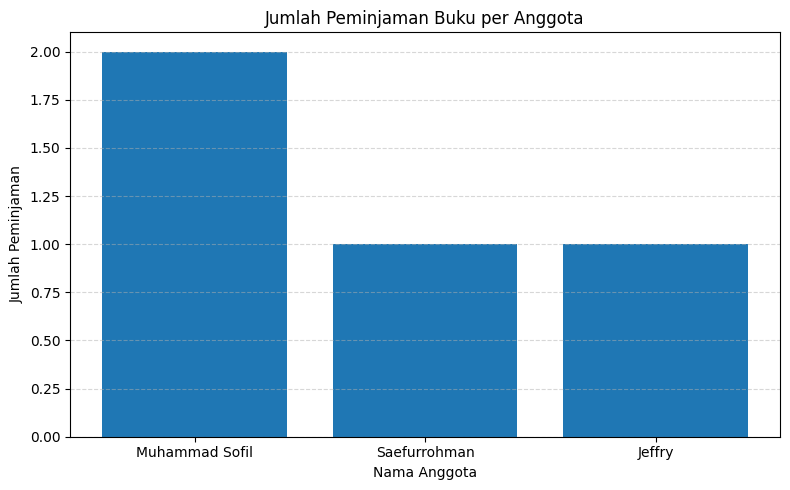

In [12]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_jumlah['nama_anggota'],
    df_jumlah['jumlah_peminjaman']
)

plt.title('Jumlah Peminjaman Buku per Anggota')
plt.xlabel('Nama Anggota')
plt.ylabel('Jumlah Peminjaman')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

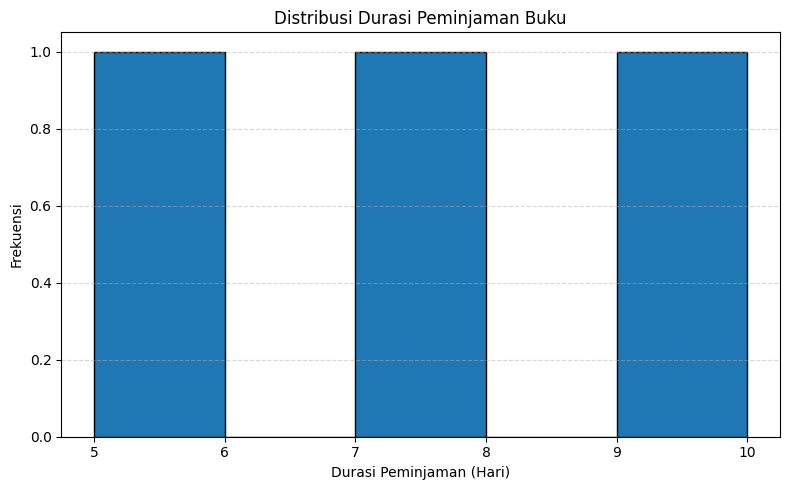

In [13]:
# Mengambil data yang memiliki durasi peminjaman
durasi_valid = df_peminjaman['durasi_pinjam'].dropna()

plt.figure(figsize=(8, 5))

plt.hist(
    durasi_valid,
    bins=5,
    edgecolor='black'
)

plt.title('Distribusi Durasi Peminjaman Buku')
plt.xlabel('Durasi Peminjaman (Hari)')
plt.ylabel('Frekuensi')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Kesimpulan

Berdasarkan hasil pembuatan sistem basis data perpustakaan menggunakan SQLite, berhasil dibuat tiga tabel yaitu buku, anggota, dan peminjaman. Sebanyak 5 data buku, 3 data anggota, dan 4 transaksi peminjaman berhasil dimasukkan ke dalam database.

Melalui operasi JOIN, informasi peminjaman dapat ditampilkan secara lengkap dengan menggabungkan nama anggota dan judul buku. Selanjutnya, GROUP BY dan fungsi COUNT digunakan untuk menghitung jumlah peminjaman setiap anggota.

Hasil eksplorasi menggunakan Pandas menunjukkan bahwa terdapat 4 transaksi peminjaman, dengan 3 buku sudah dikembalikan dan 1 buku belum dikembalikan. Rata-rata durasi peminjaman untuk buku yang sudah dikembalikan adalah 7,33 hari.

Visualisasi menggunakan Matplotlib membantu memperlihatkan jumlah peminjaman setiap anggota dan distribusi durasi peminjaman buku.